In [46]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch

In [47]:
df = pd.read_csv('SocialMemory_IT_Stim.csv')
print(df)

   Group  Familiar  Novel  Familiar.1  Novel.1 Control
0      1     85.91  72.01       69.74    96.97       n
1      2     59.43  88.27       72.56    71.80       n
2      3     73.27  70.53       58.46   108.54       n
3      4     47.85  77.18       60.58   104.79       n
4      5     54.47  98.06       45.54    85.85       n
5      6     61.76  78.34       45.06    62.71       n
6      7     41.42  61.17       62.76    87.89       n
7      8     63.62  73.35       43.34   110.52       n
8      9     67.99  96.14       70.80    83.20       n
9     10     68.11  91.53       60.38    54.92       n


In [48]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
#print(newdf)

def map_half(i,num):
    if(i < num/2):
        return 0
    return 1

/var/folders/b7/k9l5l5ss13d27wd57vb8fq4w0000gn/T/ipykernel_35960/1666696427.py:15: UserWarning: 
The palette list has fewer values (2) than needed (4) and will cycle, which may produce an uninterpretable plot.
  ax = sns.stripplot(
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


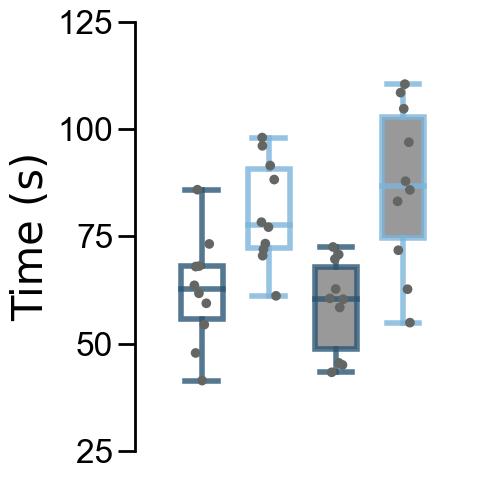

In [49]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}

text_boxplot = ['','****']

text_boxplot = ['','***']
colors = ["#646664","#646664"]
colors_boxplot = ['#2a5573', "#7db5db",'#2a5573', "#7db5db"]
colors_boxplot_filling = ['grey',"grey"]

ax = sns.stripplot(
    data=newdf,
    hue='Experimental Condition',
    size=7,
    y='Left preference',
    x='control',
    palette=colors,
    jitter=0.09,
    dodge=True
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=newdf,
    hue='Experimental Condition',
    y='Left preference',
    x='control',
    palette=colors_boxplot,
    fliersize=0,
    linewidth=4,
    **PROPS
)

#plt.axhline(linewidth=2, color='lightgrey',ls='--')

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_linewidth(2)

data_ratio = 0.4016222222466667

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

#CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches


for i, patch in enumerate(box_patches):
    
   # col = colors_boxplot[map_half(i,len(box_patches))]
    col = colors_boxplot[i]
    col_fill = colors_boxplot_filling[map_half(i,len(box_patches))]
    facecolor = col_fill if i>=2 else 'None'
    patch.set_edgecolor(col)
    patch.set_facecolor(facecolor)
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
#END CHANGE BOXPLOT STYLE

ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)

ax.set_xlabel("",fontsize=20)
ax.set_ylim([25,125])


plt.legend([],[], frameon=False)
#ax.set_xticklabels(['Control','SFC'], fontsize = 26)
#ax.set_xlabel("",fontsize=20)

ax.set_ylabel('Time (s)', fontsize = 30)
ax.set_yticks([25,50,75,100,125], fontname='Arial')
ax.set_yticklabels(['25','50','75','100','125'],fontname='Arial')


#significance(ax,1,data_ratio,newdf.loc[newdf['control']=='n']['Left preference'].max()+17,text=text_boxplot[1],offset=-4,whisker=2)

ax.set_xticks([])
ax.tick_params(axis='y', which='major', direction='out',length=12, labelsize=24, width=2)
plt.title("", fontsize=24,y=1.05)


fig = ax.get_figure()
adjust_box_widths(fig, 0.65)
fig.set_size_inches(4.9,4.9)

plt.tight_layout()
fig.tight_layout()
fig.savefig("SocialMemory_IT_Stim.jpg",dpi=500,bbox_inches='tight')
plt.savefig('SocialMemory_IT_Stim.eps', format='eps')

